### Goals

- load models trained with different setups
- with each model, predict the test set  
- compute metrics







In [3]:
import sys
import matplotlib.pyplot as plt
from IPython.display import clear_output
import json
import itertools 
import os 
import random
import matplotlib.pyplot as plt
import pprint
sys.path.append('../')
import tqdm
from pprint import pformat
import pickle

from sklearn.metrics import classification_report
import torch.nn as nn
import rasterio
import numpy as np
import torch
import torch.nn.functional as F
import utils
import pandas as pd
import geopandas as gpd

import model.dataloader as dataloader
from model.dataset import LABEL_MAPPING
from model.model import MultiModalDriverClassifier

import wandb

inverse_label_mapping = {value : key for key, value in LABEL_MAPPING.items()}

In [4]:
import sys
sys.path.append('../')
from evaluate import compute_and_log_metrics

In [5]:
# Define the filter criteria
filter_criteria = {
    #'config.image_encoder.use': True,
    #'config.tabular_encoder.use': True,
    #'config.loc_encoder.use': True,
    

    "group" : "27/9 modalities ",
    #"group" : "18/9 modalities",
    #"group" : "11/9 loc encoders",

    #"config.seed" : 420,
    #"$and": [{
    #'created_at': {
    #        "$lt": '2024-06-24T00',
    #        "$gt": '2024-06-01T17'
    #    }
    #}]

    
}





In [8]:
models = utils.get_wandb_runs(filter_criteria)

print(f'models: {len(models)}')

models: 245


In [27]:
'''
In some cases, the wandb API filtering doesn't work;
If I get 0 models returned, I need to 
    1. remove the problematic filter
    2. get all the runs
    3. filter manually as below
'''
#Example:
#models = [model for model in models  if model['config']['seed'] == 422]  
#models = [model for model in models  if model['config']['train_dst_size'] == 10000]  
#models = [model for model in models  if model['config']['image_encoder']['use']]  
#models = [model for model in models  if model['config']['image_encoder']['use']]  
#print(len(selected_models))
#models = selected_models

In [28]:
print(len(models))

20


In [29]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
n_classes = 11


In [30]:
CHECKPOINT_TYPE = 'last'

for i, model_dict in enumerate(tqdm.tqdm(models)):
    #if i < 42:
    #    continue
    #if i > 2:
    #    break
    
    #This is just to get rid of wandb objects that are un-picklable wtf
    model_dict['summary'] = None
    
    try:
        metrics, preds = utils.load_model_and_predict(model_dict, n_classes, device, 'val', CHECKPOINT_TYPE)
    except Exception as e:
        print(e)
        continue
    model_dict['predictions'] = preds
    model_dict['metrics'] = metrics
    
    #try:
    #    model_dict['summary']['_wandb'] = dict(model_dict['summary']['_wandb'])
    #    model_dict['summary']['val conf matrix'] = None
    #    model_dict['summary']['train conf matrix'] = None
    #except KeyError:
    #    pass
    

100%|█████████████████████████████████████████████████████████████████████████| 20/20 [04:24<00:00, 13.23s/it]


In [9]:
##### selected_models = [model for model in models  if model['config']['train_examples_per_class'] < 1000]  


In [76]:
def inspect_objects(d, path=""):
    if isinstance(d, dict):
        for k, v in d.items():
            new_path = f"{path}/{k}" if path else str(k)
            inspect_objects(v, new_path)
    elif isinstance(d, list):
        for i, item in enumerate(d):
            new_path = f"{path}/{i}"
            inspect_objects(item, new_path)
    elif isinstance(d, tuple):
        for i, item in enumerate(d):
            new_path = f"{path}/{i}"
            inspect_objects(item, new_path)
    else:
        print(f"Object at path {path}: {type(d)}")

In [11]:

#filename = '26_7_eval_on_test_set'

#filename = '29_7_eval_on_test_set'
#filename_2 = '30_7_eval_on_test_set'
#filename = '30_7_eval_on_test_set_seed_422to425'
#filename = '5_8_eval_on_test_set_one_img'
#filename = '8_8_eval_on_test_set_one_img'
#filename = '9_8_eval_on_test_set_one_img'
#filename = '9_8_eval_on_test_set_four_img'
filename = '27_9_modalities'


In [6]:
len(models)

NameError: name 'models' is not defined

In [17]:
with open(f'{filename}.pickle', 'wb') as handle:
    pickle.dump(models, handle, protocol=pickle.HIGHEST_PROTOCOL)

In [18]:
with open('27_9_modalities_backup.pickle', 'wb') as handle:
    pickle.dump(models, handle, protocol=pickle.HIGHEST_PROTOCOL)

In [12]:


with open(f'{filename}.pickle', 'rb') as handle:
    other_models = pickle.load(handle)


In [8]:
#models = other_models + models

In [15]:
#models = [model for model in other_models  if model['config']['two_model_regularization']['use'] == False]
#models = [model for model in models  if model['config']['model_version'] == 'v1']




In [13]:
models_ = [model for model in other_models if model['config'] != {}]
models__ = [model for model in models_ if 'metrics' in model.keys()]


In [14]:
len(models__)

245

In [32]:
hyperparams_values = utils.find_keys_with_multiple_values([model['config'] for model in models])

In [33]:
hyperparams_values

{'seed': [420, 422, 423, 424, 425],
 'loc_encoder': {'use': [False, True]},
 'tabular_encoder': {'use': [False, True]}}

In [34]:
labels = pd.read_csv("/home/jan/Documents/EPFL/project_2/data/labels/dataset_v5/labels_no_regrowth.csv")
labels = labels.loc[labels['split'] == 4].reset_index(drop=True) # Get test examples 

targets = labels['driver'].map(LABEL_MAPPING).to_numpy()


In [35]:
def get_models_with_config(_models, target_config):
    
    def has_key_value_pair(d, target):
        if isinstance(d, dict) and isinstance(target, dict):
            for key, value in target.items():
                if key in d:
                    if isinstance(value, dict) and isinstance(d[key], dict):
                        if not has_key_value_pair(d[key], value):
                            return False
                    else:
                        if d[key] != value:
                            return False
                else:
                    return False
            return True
        return d == target
    
    models_with_this_config_combination = []
    for model in _models:
        skip_model = False
        for key in target_config.keys():
            if not has_key_value_pair(model['config'][key],target_config[key]):
            #if model['config'][key] != target_config[key]:
                skip_model = True
                break
        if skip_model:
            continue
        models_with_this_config_combination.append(model)
    
    return models_with_this_config_combination

In [27]:
exclude_keys = ['seed']

combinations = utils.generate_combinations(hyperparams_values, exclude_keys)

In [28]:
#This I need to do in case there is only 1 seed
#hyperparams_values['seed'] = [420]

In [29]:

performance_per_configuration = {}

for combo in combinations:
    
    metrics_per_random_seed = []
    combo_str = ' '.join(pformat(combo, width=1).split())
    #print(combo_str)

    #Compute metrics per each random seed separately
    for seed in hyperparams_values['seed']:
        combo['seed'] = seed 
        
        #Get all models that have the configuration setup 
        model_with_this_config = get_models_with_config(models, combo)
        if not model_with_this_config:
            continue

            
        assert len(model_with_this_config) == 1, f"there should be 1 model with a config, found {len(model_with_this_config)}"
        model_with_this_config = model_with_this_config[0]
        if not 'metrics' in model_with_this_config.keys():
            continue
            
            
        metrics_per_random_seed.append(pd.DataFrame(model_with_this_config['metrics']))


    if not metrics_per_random_seed:
        print("no metrics for: ", combo)
        continue


    # Concatenate DataFrames along a new axis
    concat_df = pd.concat(metrics_per_random_seed, keys=range(len(metrics_per_random_seed)))

    # Compute the mean along the new axis
    mean_df = concat_df.groupby(level=1).mean()

    # Compute the standard deviation along the new axis
    std_df = concat_df.groupby(level=1).std()   
    
    

    performance_per_configuration[combo_str] = {}
    performance_per_configuration[combo_str]['mean'] = mean_df
    performance_per_configuration[combo_str]['std'] = std_df



        

no metrics for:  {'loc_encoder': {'use': False}, 'image_encoder': {'use': False}, 'tabular_encoder': {'use': False}, 'train_dataset_total_size': 100, 'seed': 425}
no metrics for:  {'loc_encoder': {'use': False}, 'image_encoder': {'use': False}, 'tabular_encoder': {'use': False}, 'train_dataset_total_size': 1000, 'seed': 425}
no metrics for:  {'loc_encoder': {'use': False}, 'image_encoder': {'use': False}, 'tabular_encoder': {'use': False}, 'train_dataset_total_size': 5000, 'seed': 425}
no metrics for:  {'loc_encoder': {'use': False}, 'image_encoder': {'use': False}, 'tabular_encoder': {'use': False}, 'train_dataset_total_size': 200, 'seed': 425}
no metrics for:  {'loc_encoder': {'use': False}, 'image_encoder': {'use': False}, 'tabular_encoder': {'use': False}, 'train_dataset_total_size': 10000, 'seed': 425}
no metrics for:  {'loc_encoder': {'use': False}, 'image_encoder': {'use': False}, 'tabular_encoder': {'use': False}, 'train_dataset_total_size': 2000, 'seed': 425}
no metrics for:  

In [30]:
#performance_per_configuration = {key:value for key, value in performance_per_configuration.items() if "{'model_version': 'v2', 'tabular_encoder': {'use': False}" not in key}


In [31]:
models_100_dst = {key:value for key, value in performance_per_configuration.items() if "'train_dataset_total_size': 100}" in key}
models_200_dst = {key:value for key, value in performance_per_configuration.items() if "'train_dataset_total_size': 200}" in key}
models_500_dst = {key:value for key, value in performance_per_configuration.items() if "'train_dataset_total_size': 500}" in key}
models_1000_dst = {key:value for key, value in performance_per_configuration.items() if "'train_dataset_total_size': 1000}" in key}
models_2000_dst = {key:value for key, value in performance_per_configuration.items() if "'train_dataset_total_size': 2000}" in key}
models_5000_dst = {key:value for key, value in performance_per_configuration.items() if "'train_dataset_total_size': 5000}" in key}
models_10000_dst = {key:value for key, value in performance_per_configuration.items() if "'train_dataset_total_size': 10000}" in key}
#models_20000_dst = {key:value for key, value in performance_per_configuration.items() if "'train_dataset_total_size': 20000}" in key}


In [54]:
def plot_metrics(metrics, metric='accuracy', ylim=(0.2, 1.2) ):
    
    #class_names = list(LABEL_MAPPING.keys())
    class_names = ['weighted avg', 'macro avg']
    class_names.append(metric)
    stats = {}
    for model_name, model_stats in metrics.items():
        stats[model_name] = {}
        for cls in class_names:
            stats[model_name][cls] = {}
            stats[model_name][cls]['score'] = metrics[model_name]['mean'][cls]['f1-score']
            stats[model_name][cls]['std'] = metrics[model_name]['std'][cls]['f1-score']

    # Initialize plot
    fig, ax = plt.subplots(figsize=(12, 6))

    # Set the width of the bars
    bar_width = 0.7/len(metrics)

    # Set positions of the bars on the x-axis
    index = np.arange(len(class_names))

    # Plot each model's data

    #for i, model in enumerate(stats.keys()):
    for i, model in enumerate(list(metrics.keys())): #only models with image
        scores = [stats[model][cls]['score'] for cls in class_names]
        stds = [stats[model][cls]['std'] for cls in class_names]
        ax.bar(index + i * bar_width, scores, bar_width, label=model, yerr=stds, capsize=5)

    # Set labels, title, and legend
    #ax.set_xlabel('Class')
    #ax.set_ylabel('Score')
    plt.ylim(bottom=ylim[0])
    plt.ylim(top=ylim[1])
    ax.set_xticks(index + bar_width / 2)
    ax.set_xticklabels(class_names, rotation=45, ha='right')
    #ax.legend()

    # Show plot
    plt.tight_layout()
    plt.show(
    )

{"{'image_encoder': {'use': False}, 'loc_encoder': {'use': False}, 'tabular_encoder': {'use': True}, 'train_dataset_total_size': 10000}": {'mean':               pasture  forest plantation         soy      coffee    palm oil  \
  f1-score     0.215588                0.0    0.426239    0.497669    0.584901   
  precision    0.170941                0.0    0.301259    0.892043    0.645148   
  recall       0.299526                0.0    0.786848    0.345455    0.538462   
  support    422.000000              209.0  441.000000  198.000000  416.000000   
  
             mining       urban        cocoa      rubber  shifting agriculture  \
  f1-score      0.0    0.012138     0.610916    0.652670              0.409794   
  precision     0.0    0.082511     0.853516    0.787925              0.267079   
  recall        0.0    0.006950     0.512129    0.559560              1.000000   
  support     532.0  259.000000  1113.000000  455.000000            281.000000   
  
                  other  accu

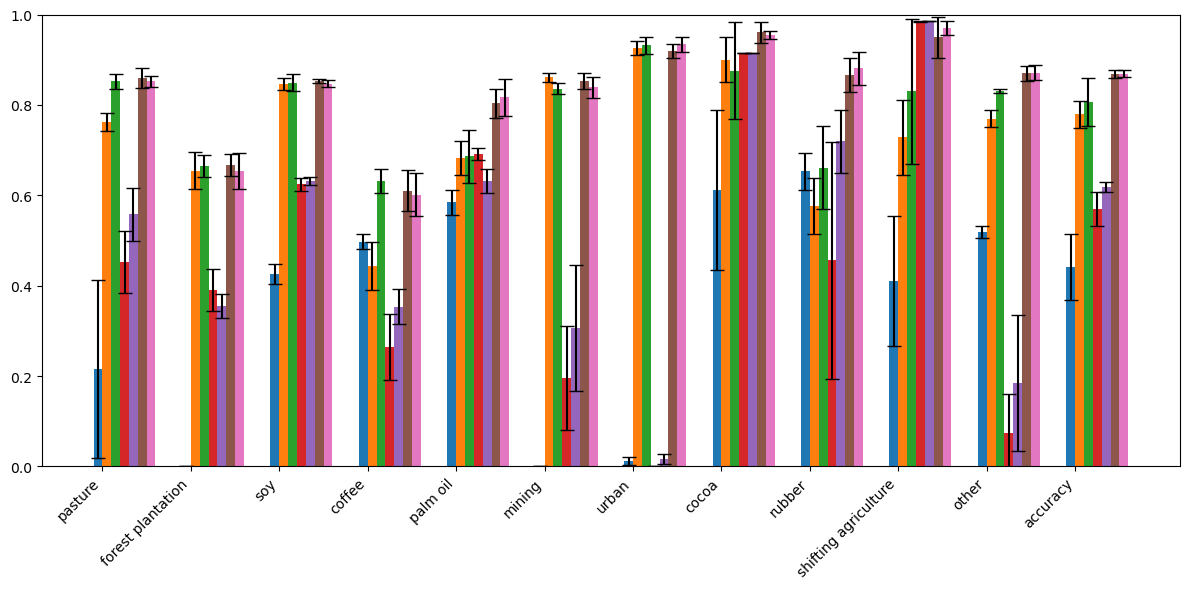

In [55]:
plot_metrics(models_10000_dst, ylim=(0, 1))

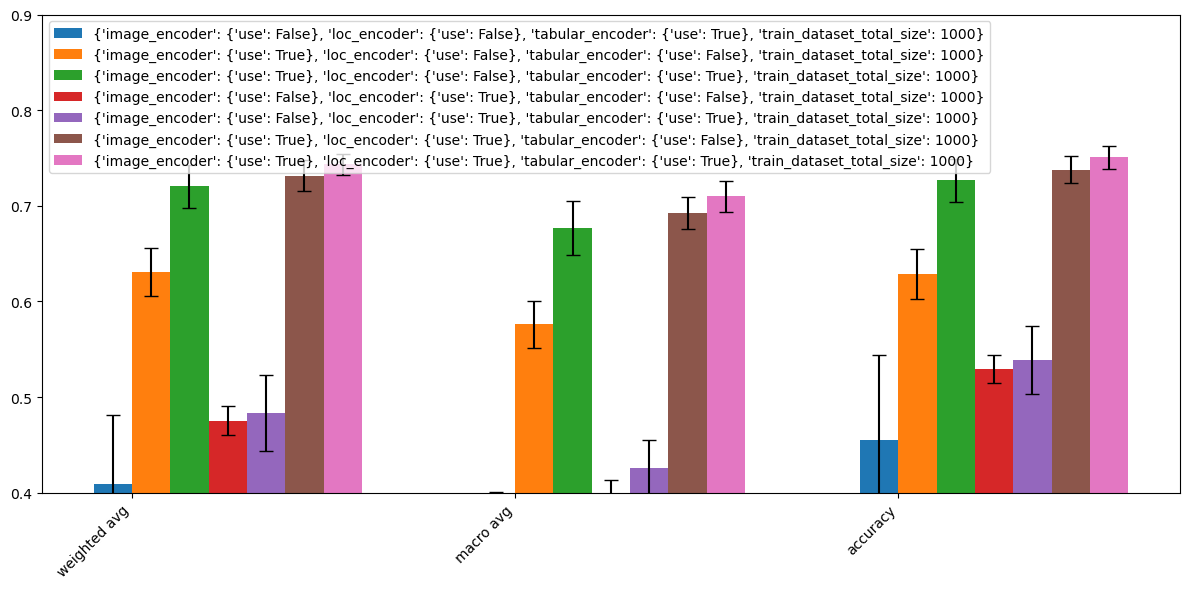

In [22]:
plot_metrics(models_1000_dst, ylim=(0.4, 0.9))

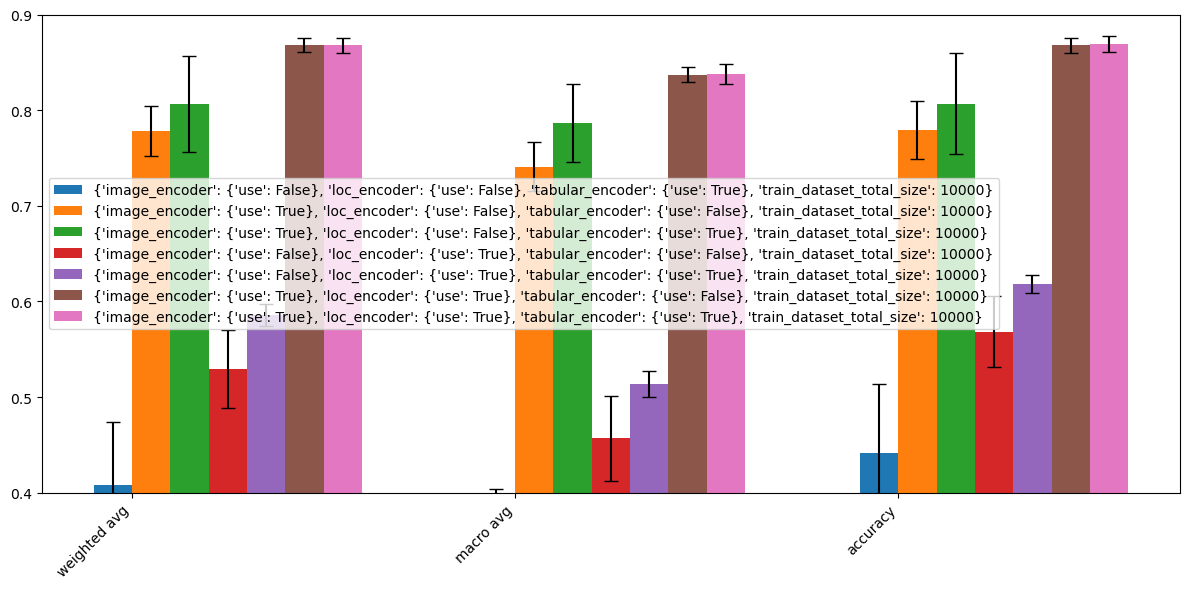

In [42]:
plot_metrics(models_10000_dst, ylim=(0.4, 0.9))

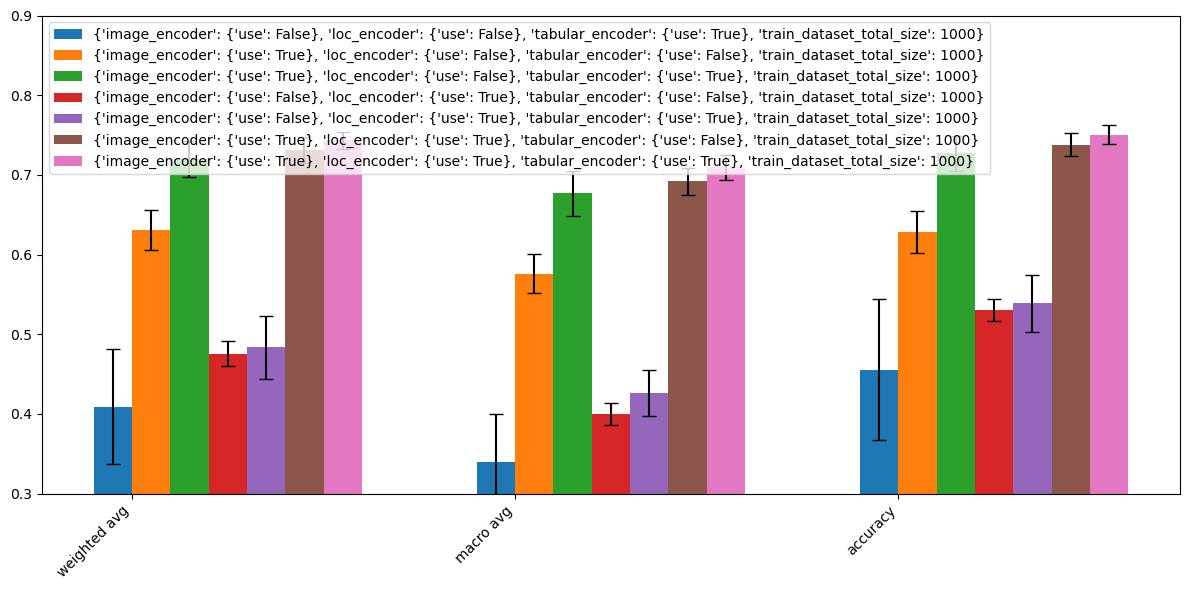

In [35]:
plot_metrics(models_1000_dst, ylim=(0.3, 0.9))

['cocoa',
 'coffee',
 'forest plantation',
 'mining',
 'other',
 'palm oil',
 'pasture',
 'rubber',
 'shifting agriculture',
 'soy',
 'urban']

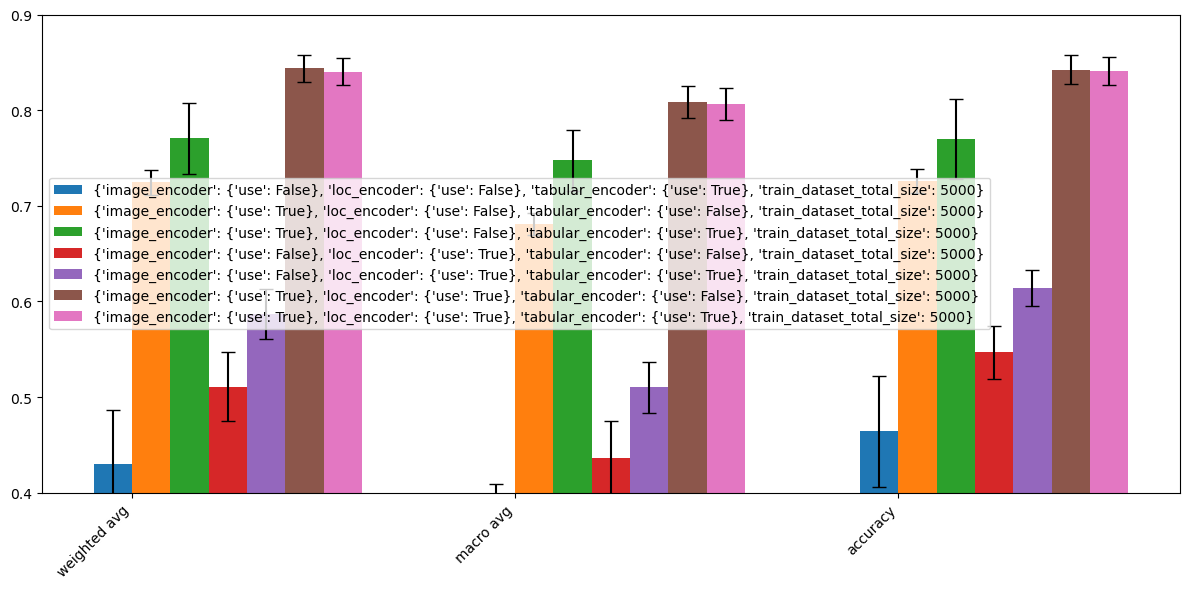

In [29]:
plot_metrics(models_5000_dst, ylim=(0.4, 0.9))

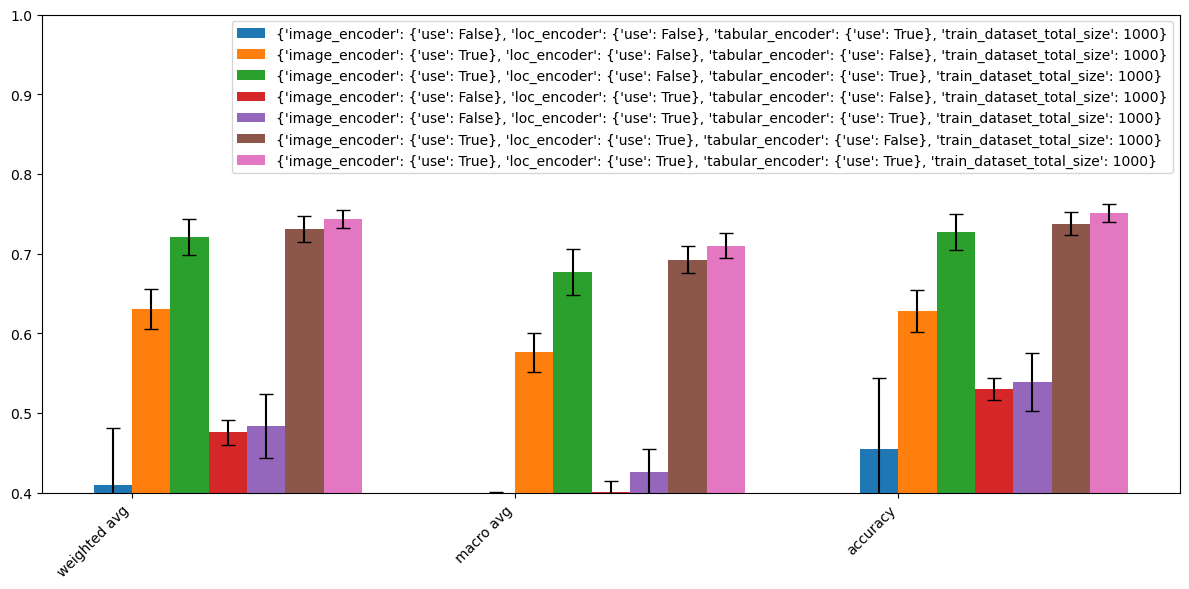

In [36]:
plot_metrics(models_1000_dst, ylim=(0.4, 1))

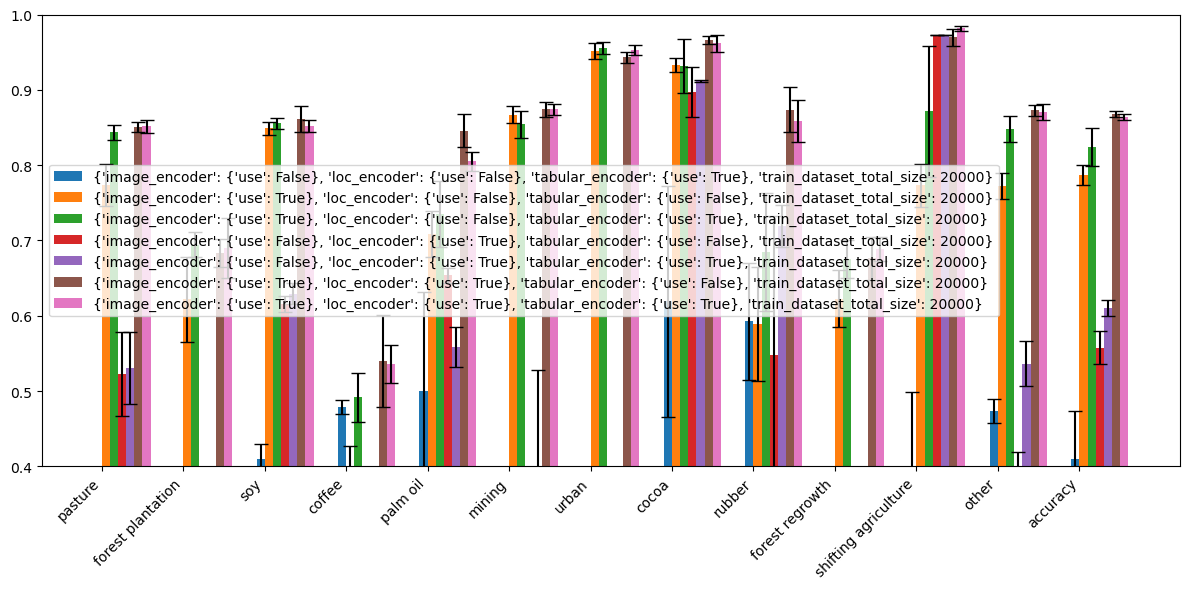

In [114]:
plot_metrics(models_20000_dst, ylim=(0.4, 1))

In [66]:
performance_per_configuration["{'image_encoder': {'use': True}, 'loc_encoder': {'use': True}, 'tabular_encoder': {'use': True}, 'train_dataset_total_size': 500}"]['mean']

,pasture,forest plantation,soy,coffee,palm oil,mining,urban,cocoa,rubber,shifting agriculture,other,accuracy,macro avg,weighted avg,loss
f1-score,0.725625,0.438589,0.716233,0.374233,0.388325,0.690914,0.707506,0.919180,0.449014,0.912813,0.647592,0.69367,0.633639,0.685984,1.319481
precision,0.692040,0.361854,0.698139,0.365416,0.435837,0.730283,0.809687,0.863323,0.626526,0.910335,0.666880,0.69367,0.650938,0.697218,1.319481
recall,0.776303,0.577033,0.737868,0.389899,0.351923,0.657895,0.631660,0.982929,0.358242,0.920996,0.633566,0.69367,0.638029,0.693670,1.319481
support,422.000000,209.000000,441.000000,198.000000,416.000000,532.000000,259.000000,1113.000000,455.000000,281.000000,429.000000,0.69367,4755.000000,4755.000000,1.319481


In [72]:
import ast
import re


# Function to remove 'seed' key-value pairs from a string representation of a dictionary
def remove_seed(entry):
    # Remove the seed key-value pair using regular expressions
    cleaned_entry = re.sub(r"'seed': \d+,? ?", "", entry)
    return cleaned_entry

In [73]:
performance_per_configuration_renamed = {}

for key, value in performance_per_configuration.items():
    performance_per_configuration_renamed[remove_seed(key)] = value
    

In [74]:
def process_stats_all(___models, metric='accuracy', n_examples_list=[200, 500, 1000, 2000, 5000, 10000, 20000]):

    _models_stats = {}
    
    keys_to_delete = []

    _models_stats["{'image_encoder': {'use': False}, 'loc_encoder': {'use': True}, 'tabular_encoder': {'use': False}, xx}"] = {'acc' : [], 'std': []}
    _models_stats["{'image_encoder': {'use': False}, 'loc_encoder': {'use': False}, 'tabular_encoder': {'use': True}, xx}"] = {'acc' : [], 'std': []}
    _models_stats["{'image_encoder': {'use': False}, 'loc_encoder': {'use': True}, 'tabular_encoder': {'use': True}, xx}"] = {'acc' : [], 'std': []}
    
    _models_stats["{'image_encoder': {'use': True}, 'loc_encoder': {'use': False}, 'tabular_encoder': {'use': False}, xx}"] = {'acc' : [], 'std': []}
    _models_stats["{'image_encoder': {'use': True}, 'loc_encoder': {'use': True}, 'tabular_encoder': {'use': False}, xx}"] = {'acc' : [], 'std': []}
    _models_stats["{'image_encoder': {'use': True}, 'loc_encoder': {'use': False}, 'tabular_encoder': {'use': True}, xx}"] = {'acc' : [], 'std': []}
    _models_stats["{'image_encoder': {'use': True}, 'loc_encoder': {'use': True}, 'tabular_encoder': {'use': True}, xx}"] = {'acc' : [], 'std': []}
    
    #_models_stats["{'tabular_encoder': {'use': True}, xx}"] = {'acc' : [], 'std': []}
    #_models_stats["{'tabular_encoder': {'use': False}, xx}"] = {'acc' : [], 'std': []}

    for n_examples in n_examples_list:

        #for key in _models.keys():
        selected_models = {key:value for key, value in ___models.items() if f"'train_dataset_total_size': {n_examples}}}" in key}
        for key in _models_stats.keys():
            model_name = key.replace("xx", f"'train_dataset_total_size': {n_examples}") 
            try:
                sel_model = selected_models[model_name]
            except KeyError:
                keys_to_delete.append(key)
                continue
            acc = sel_model['mean'][metric]['f1-score']
            std = sel_model['std'][metric]['f1-score']
            _models_stats[key]['acc'].append(acc)
            _models_stats[key]['std'].append(std)

    for key in list(set(keys_to_delete)):
        del _models_stats[key]
        
    return _models_stats
    

In [65]:
#_models_stats_reg = process_stats_reg(reg_models)
#_models_stats_all = process_stats_all(performance_per_configuration_renamed)
#_models_f1 = process_stats_all(performance_per_configuration_renamed, 'macro avg')



In [69]:


run_names_mapping = {
    "{'image_encoder': {'use': False}, 'loc_encoder': {'use': True}, 'tabular_encoder': {'use': False}, xx}" : "loc",
    "{'image_encoder': {'use': False}, 'loc_encoder': {'use': False}, 'tabular_encoder': {'use': True}, xx}" : "tab",
    "{'image_encoder': {'use': False}, 'loc_encoder': {'use': True}, 'tabular_encoder': {'use': True}, xx}" : "loc+tab",
    "{'image_encoder': {'use': True}, 'loc_encoder': {'use': False}, 'tabular_encoder': {'use': False}, xx}" : "image",
    "{'image_encoder': {'use': True}, 'loc_encoder': {'use': True}, 'tabular_encoder': {'use': False}, xx}" : "image + location",
    "{'image_encoder': {'use': True}, 'loc_encoder': {'use': False}, 'tabular_encoder': {'use': True}, xx}" : "image + tabular",
    "{'image_encoder': {'use': True}, 'loc_encoder': {'use': True}, 'tabular_encoder': {'use': True}, xx}" : "image + location + tabular"
}

In [67]:

def _plot_dict(_dict, x_axis_vals, names=run_names_mapping):
    for key, value in _dict.items():
        acc = value['acc']
        std = value['std']
        plt.errorbar(x_axis_vals, acc, yerr=std, label=names[key], capsize=5)

    plt.xlabel('Training dataset size')
    plt.ylabel('Accuracy')
    plt.title('Modality comparison')
    plt.legend(bbox_to_anchor=(1.,1))
    plt.xscale('log')
    plt.grid(True)
    plt.show()

In [68]:
def plot_metric(_model_stats, metric, run_names=run_names_mapping, n_examples=[200, 500, 1000, 2000, 5000, 10000, 20000]):
    
    processed_stats = process_stats_all(_model_stats, metric, n_examples_list=n_examples)
    
    _plot_dict(processed_stats, n_examples,run_names)

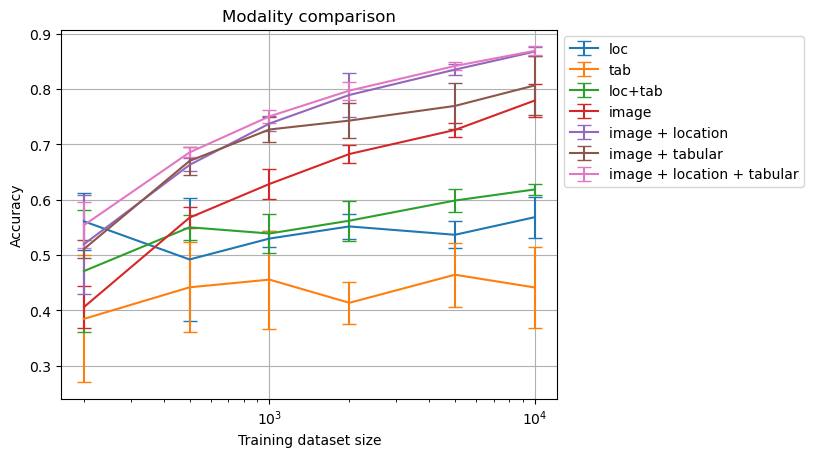

In [166]:
plot_metric(performance_per_configuration_renamed, 'accuracy', run_names_mapping, n_examples=[200, 500, 1000, 2000, 5000, 10000])


In [70]:
def _plot_dict2(_dict, x_axis_vals, names=run_names_mapping):
    #x_indices = range(len(x_axis_vals))  # Create equal spacing for x-axis

    for key, value in _dict.items():
        acc = value['acc']
        std = value['std']

        plt.plot(x_axis_vals, acc, label=names[key])
        plt.fill_between(x_axis_vals, [a - s for a, s in zip(acc, std)], [a + s for a, s in zip(acc, std)], alpha=0.2)

    #plt.xticks(x_indices, x_axis_vals)  # Set x-axis ticks to the original x_axis_vals
    plt.xlabel('Training dataset size')
    plt.ylabel('Accuracy')
    plt.title('Modality comparison')
    plt.legend(bbox_to_anchor=(1.,1))
    plt.xscale('log')
    plt.grid(True)
    plt.show()

In [71]:
def plot_metric_v2(_model_stats, metric, run_names=run_names_mapping, n_examples=[200, 500, 1000, 2000, 5000, 10000, 20000]):
    
    processed_stats = process_stats_all(_model_stats, metric, n_examples_list=n_examples)
    
    _plot_dict2(processed_stats, n_examples,run_names)

In [72]:
perf_with_image = {k:v for k,v in performance_per_configuration_renamed.items() if "{'image_encoder': {'use': True}" in k}



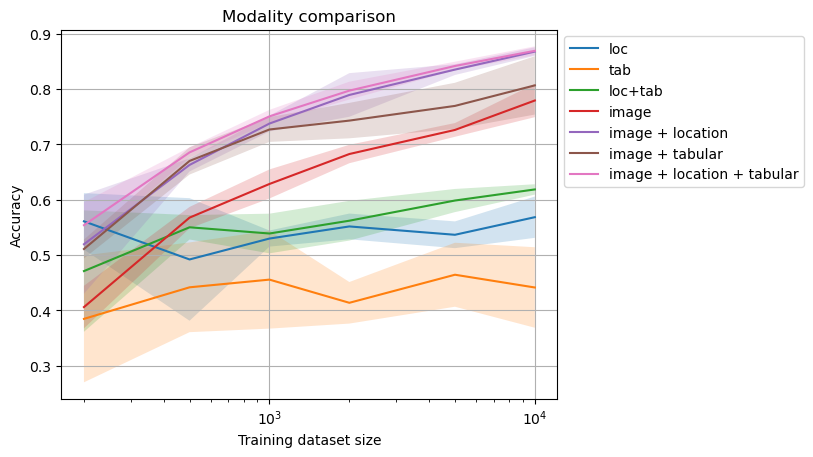

In [73]:
plot_metric_v2(performance_per_configuration_renamed, 'accuracy', run_names_mapping, n_examples=[200, 500, 1000, 2000, 5000, 10000])


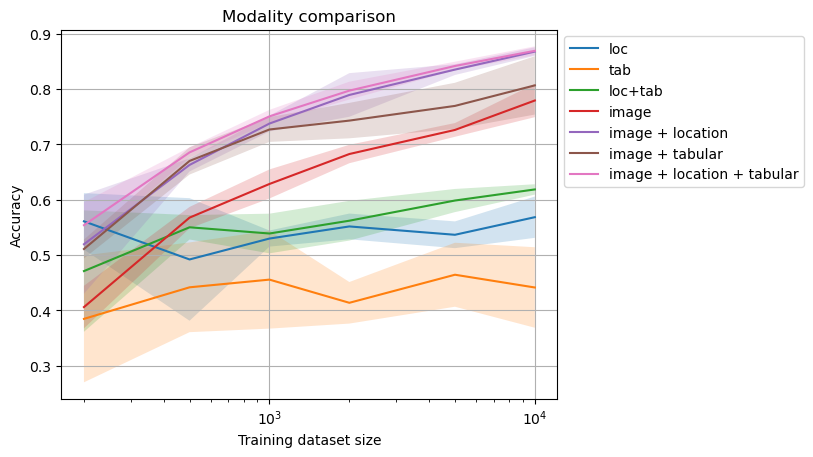

In [176]:
plot_metric_v2(performance_per_configuration_renamed, 'accuracy', run_names_mapping, n_examples=[200, 500, 1000, 2000, 5000, 10000])


### Final figure


In [70]:
def plot_metric_v2(_model_stats, metric, run_names=run_names_mapping, n_examples=[200, 500, 1000, 2000, 5000, 10000, 20000]):
    
    processed_stats = process_stats_all(_model_stats, metric, n_examples_list=n_examples)
    
    _plot_dict2(processed_stats, n_examples,run_names)
    
    
def _plot_dict2(_dict, x_axis_vals, names=run_names_mapping):
    #x_indices = range(len(x_axis_vals))  # Create equal spacing for x-axis

    for key, value in _dict.items():
        acc = value['acc']
        std = value['std']

        plt.plot(x_axis_vals, acc, label=names[key])
        plt.fill_between(x_axis_vals, [a - s for a, s in zip(acc, std)], [a + s for a, s in zip(acc, std)], alpha=0.2)

    #plt.xticks(x_indices, x_axis_vals)  # Set x-axis ticks to the original x_axis_vals
    plt.xlabel('Training dataset size')
    plt.ylabel('Accuracy')
    plt.title('Modality comparison')
    plt.legend(bbox_to_anchor=(1.,1))
    plt.xscale('log')
    plt.grid(True)
    plt.show()

In [75]:
processed_stats = process_stats_all(performance_per_configuration_renamed, 'accuracy', n_examples_list=[200, 500, 1000, 2000, 5000, 10000])


In [76]:


run_names_mapping = {
    "{'image_encoder': {'use': False}, 'loc_encoder': {'use': True}, 'tabular_encoder': {'use': False}, xx}" : "location",
    "{'image_encoder': {'use': False}, 'loc_encoder': {'use': False}, 'tabular_encoder': {'use': True}, xx}" : "tabular",
    "{'image_encoder': {'use': False}, 'loc_encoder': {'use': True}, 'tabular_encoder': {'use': True}, xx}" : "location + tabular",
    "{'image_encoder': {'use': True}, 'loc_encoder': {'use': False}, 'tabular_encoder': {'use': False}, xx}" : "image",
    "{'image_encoder': {'use': True}, 'loc_encoder': {'use': True}, 'tabular_encoder': {'use': False}, xx}" : "image + location",
    "{'image_encoder': {'use': True}, 'loc_encoder': {'use': False}, 'tabular_encoder': {'use': True}, xx}" : "image + tabular",
    "{'image_encoder': {'use': True}, 'loc_encoder': {'use': True}, 'tabular_encoder': {'use': True}, xx}" : "image + location + tabular"
}

In [77]:
for key, value in processed_stats.items():
    print(key)

{'image_encoder': {'use': False}, 'loc_encoder': {'use': True}, 'tabular_encoder': {'use': False}, xx}
{'image_encoder': {'use': False}, 'loc_encoder': {'use': False}, 'tabular_encoder': {'use': True}, xx}
{'image_encoder': {'use': False}, 'loc_encoder': {'use': True}, 'tabular_encoder': {'use': True}, xx}
{'image_encoder': {'use': True}, 'loc_encoder': {'use': False}, 'tabular_encoder': {'use': False}, xx}
{'image_encoder': {'use': True}, 'loc_encoder': {'use': True}, 'tabular_encoder': {'use': False}, xx}
{'image_encoder': {'use': True}, 'loc_encoder': {'use': False}, 'tabular_encoder': {'use': True}, xx}
{'image_encoder': {'use': True}, 'loc_encoder': {'use': True}, 'tabular_encoder': {'use': True}, xx}


In [92]:
'''x_axis_vals = [200, 500, 1000, 2000, 5000, 10000]

for key, value in processed_stats.items():
    if not "'image_encoder': {'use': True}" in key:
        continue
    
    acc = value['acc']
    std = value['std']

    plt.plot(x_axis_vals, acc, label=run_names_mapping[key])
    plt.fill_between(x_axis_vals, [a - s for a, s in zip(acc, std)], [a + s for a, s in zip(acc, std)], alpha=0.1)

#plt.xticks(x_indices, x_axis_vals)  # Set x-axis ticks to the original x_axis_vals
plt.xlabel('Training dataset size')
plt.ylabel('Accuracy')
#plt.title('Modality comparison')
#plt.legend(bbox_to_anchor=(0.4,0.22), title="Input modalities", fancybox=True, ncol=2, loc="lower left")
plt.legend(bbox_to_anchor=(0.05,1),framealpha=1,  title="Input modalities",  ncol=2, loc="lower left")
plt.xscale('log')
plt.grid(True)
plt.ylim(0.4, 0.9)
plt.xlim(197, 10010)
plt.show()
#plt.savefig('../paper/modality_comparison_with_img_only.png', dpi=200, bbox_inches='tight')'''

'x_axis_vals = [200, 500, 1000, 2000, 5000, 10000]\n\nfor key, value in processed_stats.items():\n    if not "\'image_encoder\': {\'use\': True}" in key:\n        continue\n    \n    acc = value[\'acc\']\n    std = value[\'std\']\n\n    plt.plot(x_axis_vals, acc, label=run_names_mapping[key])\n    plt.fill_between(x_axis_vals, [a - s for a, s in zip(acc, std)], [a + s for a, s in zip(acc, std)], alpha=0.1)\n\n#plt.xticks(x_indices, x_axis_vals)  # Set x-axis ticks to the original x_axis_vals\nplt.xlabel(\'Training dataset size\')\nplt.ylabel(\'Accuracy\')\n#plt.title(\'Modality comparison\')\n#plt.legend(bbox_to_anchor=(0.4,0.22), title="Input modalities", fancybox=True, ncol=2, loc="lower left")\nplt.legend(bbox_to_anchor=(0.05,1),framealpha=1,  title="Input modalities",  ncol=2, loc="lower left")\nplt.xscale(\'log\')\nplt.grid(True)\nplt.ylim(0.4, 0.9)\nplt.xlim(197, 10010)\nplt.show()\n#plt.savefig(\'../paper/modality_comparison_with_img_only.png\', dpi=200, bbox_inches=\'tight\')'

### Instead of log scale, set x-ticks manually

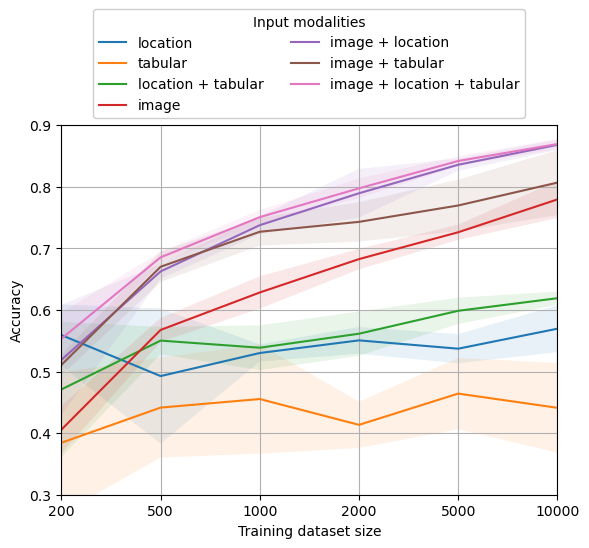

In [97]:
x_axis_vals = [200, 500, 1000, 2000, 5000, 10000]
x_indices = range(len(x_axis_vals)) 

for key, value in processed_stats.items():
    #if not "'image_encoder': {'use': True}" in key:
    #    continue
    
    acc = value['acc']
    std = value['std']

    plt.plot(x_indices, acc, label=run_names_mapping[key])
    plt.fill_between(x_indices, [a - s for a, s in zip(acc, std)], [a + s for a, s in zip(acc, std)], alpha=0.1)

plt.xticks(x_indices, x_axis_vals)  # Map ticks to equally spaced indices
plt.xlabel('Training dataset size')
plt.ylabel('Accuracy')

plt.legend(bbox_to_anchor=(0.05,1), framealpha=1, title="Input modalities", ncol=2, loc="lower left")
plt.grid(True)
plt.ylim(0.3, 0.9)
plt.xlim(0, len(x_indices)-1 )  # Adjust to fit x_indices range
#plt.show()
plt.savefig('../paper/modality_comparison.png', dpi=200, bbox_inches='tight')

In [81]:
x_indices,x_axis_vals

(range(0, 6), [200, 500, 1000, 2000, 5000, 10000])

### Alternative to per-class metrics table

- maybe having these plots per-class (over different training datasets) would be a good idea since I want to highlight the low-data regime performance

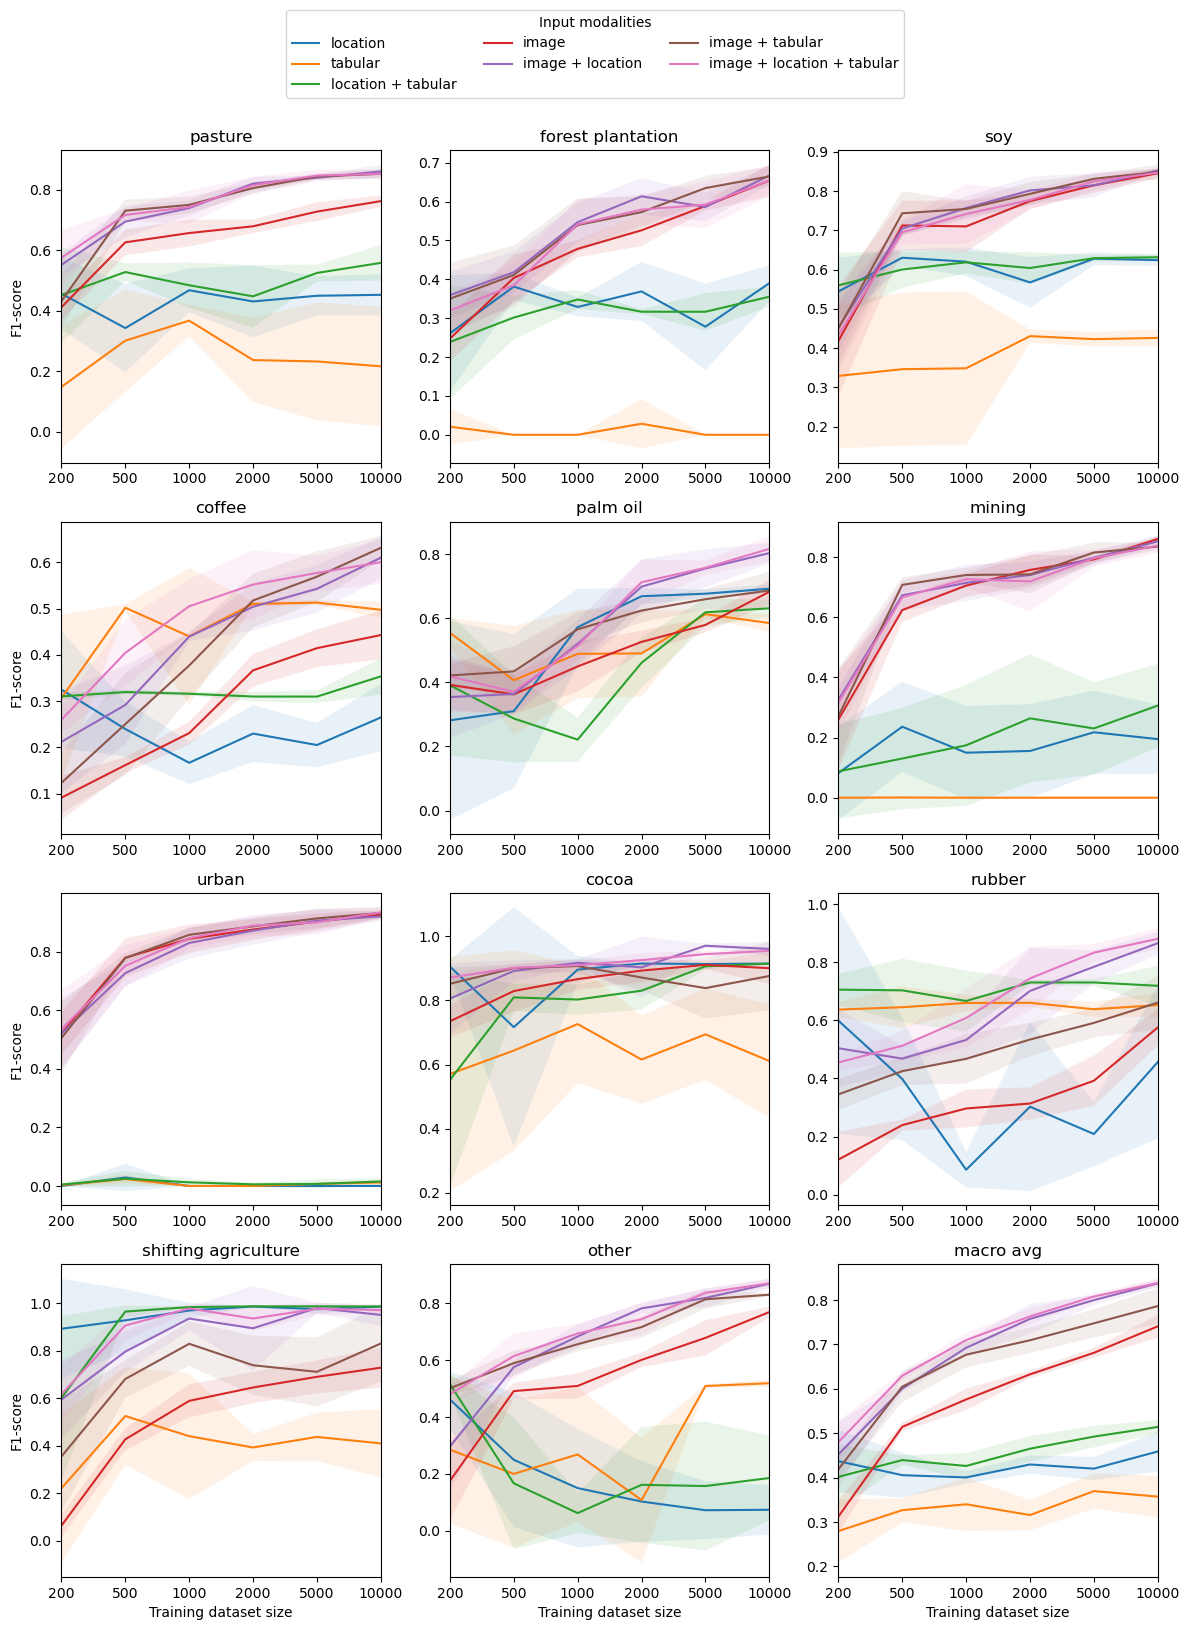

In [149]:
x_axis_vals = [200, 500, 1000, 2000, 5000, 10000]
x_indices = range(len(x_axis_vals))

fig, axes = plt.subplots(4, 3, figsize=(12, 16))

# Track unique labels for the global legend
unique_labels = {}

_idx = 0
for i in range(4):
    for j in range(3):
        try:
            _cls = list(LABEL_MAPPING.keys())[_idx]
        except IndexError:
            _cls = 'macro avg'
        

        cls_stats = process_stats_all(performance_per_configuration_renamed, _cls, n_examples_list=x_axis_vals)

        for key, value in cls_stats.items():
            #if not "'image_encoder': {'use': True}" in key:
            #    continue
            acc = value['acc']
            std = value['std']

            # Plot each line on the current subplot
            line, = axes[i, j].plot(x_indices, acc, label=run_names_mapping[key])
            axes[i, j].fill_between(x_indices, [a - s for a, s in zip(acc, std)], [a + s for a, s in zip(acc, std)], alpha=0.1)

            # Store only unique labels for global legend
            if run_names_mapping[key] not in unique_labels:
                unique_labels[run_names_mapping[key]] = line

        axes[i, j].set_xticks(x_indices)
        axes[i, j].set_xticklabels(x_axis_vals)
        #axes[i, j].set_ylim(0, 1)
        axes[i, j].set_xlim(0, len(x_indices) - 1)
        axes[i, j].set_title(_cls)
        if _idx in [0,3,6,9]:
            axes[i, j].set_ylabel('F1-score')
        if _idx in [9,10,11,12]:
            axes[i, j].set_xlabel('Training dataset size')
            
        _idx += 1
        

# Add a global legend with unique labels
fig.legend(unique_labels.values(), unique_labels.keys(), loc='upper center', title='Input modalities', bbox_to_anchor=(0.5, 1.02), ncol=3)

plt.tight_layout(rect=[0, 0, 1, 0.95])
#plt.show()
plt.savefig('../paper/modality_comparison_per_class.png', dpi=200, bbox_inches='tight')


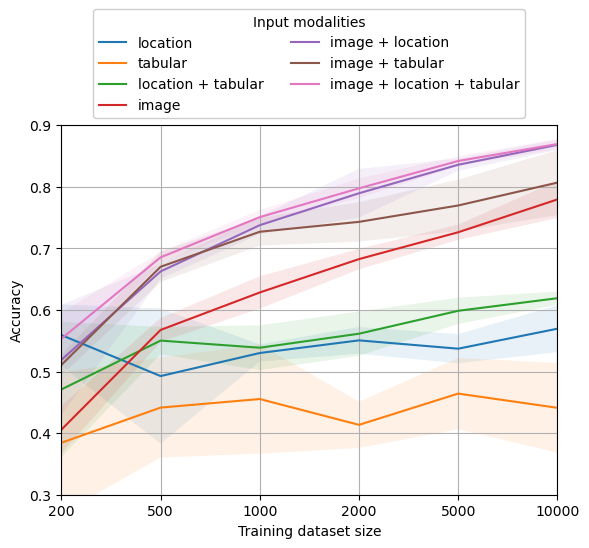

['pasture',
 'forest plantation',
 'soy',
 'coffee',
 'palm oil',
 'mining',
 'urban',
 'cocoa',
 'rubber',
 'shifting agriculture',
 'other']

In [101]:
performance_per_configuration_renamed["{'image_encoder': {'use': False}, 'loc_encoder': {'use': False}, 'tabular_encoder': {'use': True}, 'train_dataset_total_size': 100}"]



{'mean':               pasture  forest plantation         soy      coffee    palm oil  \
 f1-score     0.399820           0.088975    0.083528    0.503853    0.364661   
 precision    0.253555           0.147643    0.097576    0.877826    0.539706   
 recall       0.950711           0.132057    0.073016    0.353535    0.364904   
 support    422.000000         209.000000  441.000000  198.000000  416.000000   
 
            mining       urban        cocoa      rubber  shifting agriculture  \
 f1-score      0.0    0.046116     0.703952    0.697123               0.51316   
 precision     0.0    0.054193     0.846039    0.923526               0.35580   
 recall        0.0    0.041699     0.645822    0.560440               1.00000   
 support     532.0  259.000000  1113.000000  455.000000             281.00000   
 
                 other  accuracy    macro avg  weighted avg     loss  
 f1-score     0.196663  0.428601     0.327077      0.382086  1.65381  
 precision    0.185917  0.428601    

In [64]:
def plot_metrics_specific(metrics,  ylim=(0.2, 1.2) ):
    
    class_names = list(LABEL_MAPPING.keys())
    #class_names = ['weighted avg', 'macro avg']
    #class_names.append(metric)
    stats = {}
    for model_name, model_stats in metrics.items():
        stats[model_name] = {}
        for cls in class_names:
            stats[model_name][cls] = {}
            stats[model_name][cls]['score'] = metrics[model_name]['mean'][cls]['f1-score']
            stats[model_name][cls]['std'] = metrics[model_name]['std'][cls]['f1-score']

    # Initialize plot
    fig, ax = plt.subplots(figsize=(12, 6))

    # Set the width of the bars
    bar_width = 0.7/len(metrics)

    # Set positions of the bars on the x-axis
    index = np.arange(len(class_names))

    # Plot each model's data

    #for i, model in enumerate(stats.keys()):
    for i, model in enumerate(list(metrics.keys())): #only models with image
        scores = [stats[model][cls]['score'] for cls in class_names]
        stds = [stats[model][cls]['std'] for cls in class_names]
        ax.bar(index + i * bar_width, scores, bar_width, label=model, yerr=stds, capsize=5)

    # Set labels, title, and legend
    #ax.set_xlabel('Class')
    #ax.set_ylabel('Score')
    plt.ylim(bottom=ylim[0])
    plt.ylim(top=ylim[1])
    ax.set_xticks(index + bar_width / 2)
    ax.set_xticklabels(class_names, rotation=45, ha='right')
    ax.legend()

    # Show plot
    plt.tight_layout()
    plt.show(
    )

In [66]:
with_img_10000 = {k:v for k,v in models_10000_dst.items() if "{'image_encoder': {'use': True}" in k }
with_img_10000 = {k:v for k,v in models_1000_dst.items() if "{'image_encoder': {'use': True}" in k }

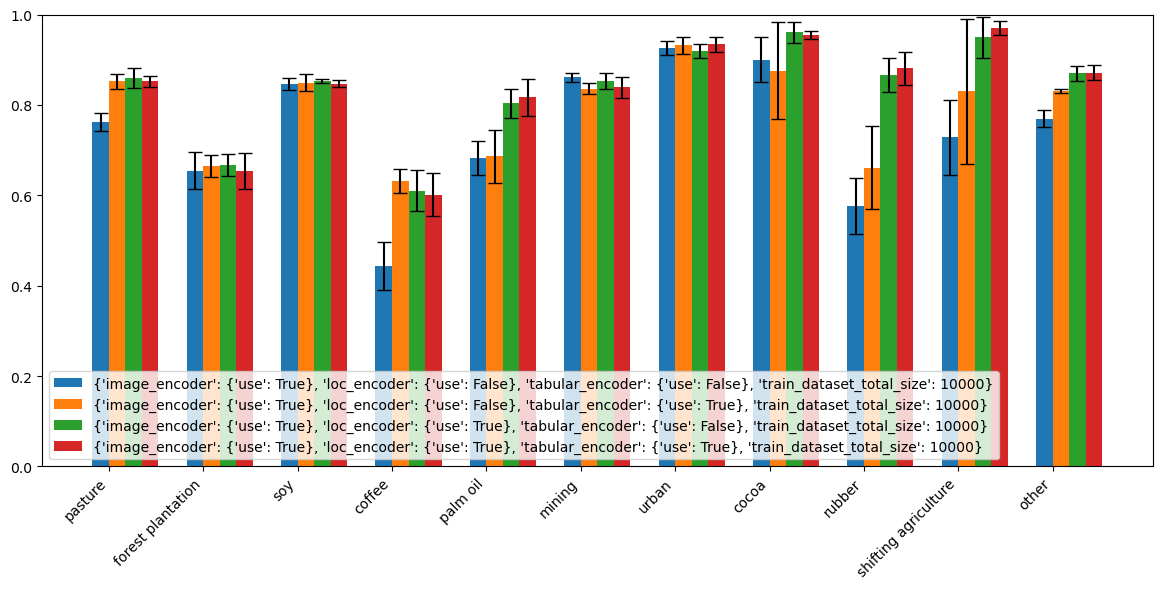

In [65]:
plot_metrics_specific(with_img_10000, ylim=(0, 1))

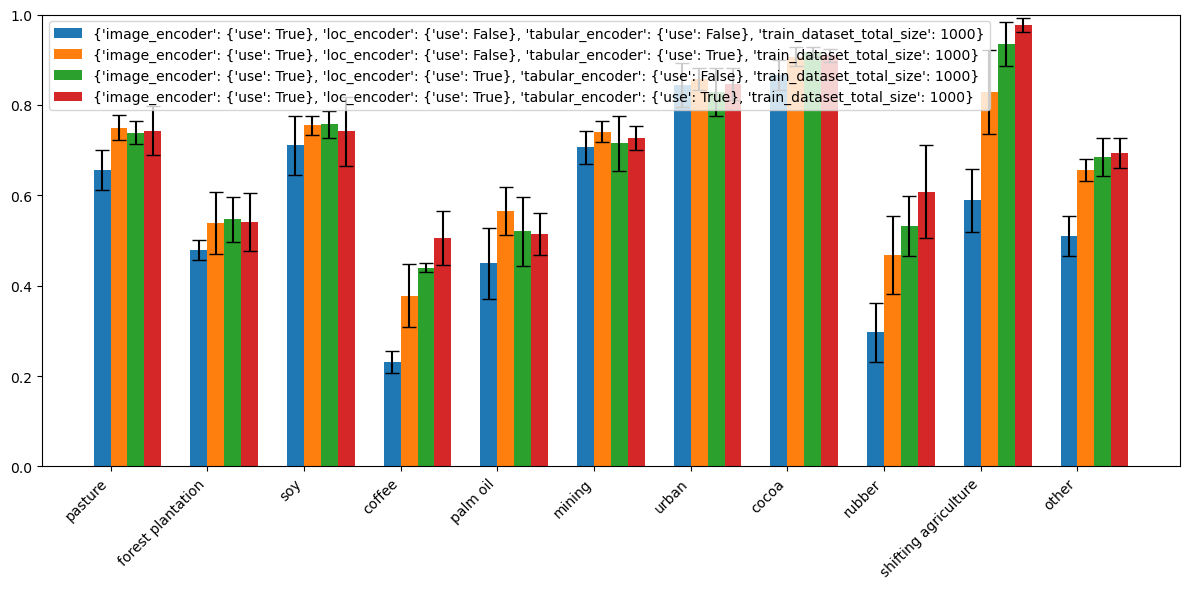

In [67]:
plot_metrics_specific(with_img_10000, ylim=(0, 1))

## Per-class metrics

In [30]:

LABEL_MAPPING = {
    'pasture' : 0, 
    'forest plantation' : 1,
    'soy' : 2,
    'coffee' : 3,
    'palm oil': 4,
    'mining': 5,
    'urban': 6,
    'cocoa': 7,
    'rubber': 8,
    'shifting agriculture': 9,
    'other': 10 
}
l = [k for k,v in LABEL_MAPPING.items()]
l.sort()
l

['cocoa',
 'coffee',
 'forest plantation',
 'mining',
 'other',
 'palm oil',
 'pasture',
 'rubber',
 'shifting agriculture',
 'soy',
 'urban']

In [41]:
models_with_img = [key for key in models_10000_dst.keys() if "{'image_encoder': {'use': True}" in key]

In [42]:
models_with_img

["{'image_encoder': {'use': True}, 'loc_encoder': {'use': False}, 'tabular_encoder': {'use': False}, 'train_dataset_total_size': 10000}",
 "{'image_encoder': {'use': True}, 'loc_encoder': {'use': False}, 'tabular_encoder': {'use': True}, 'train_dataset_total_size': 10000}",
 "{'image_encoder': {'use': True}, 'loc_encoder': {'use': True}, 'tabular_encoder': {'use': False}, 'train_dataset_total_size': 10000}",
 "{'image_encoder': {'use': True}, 'loc_encoder': {'use': True}, 'tabular_encoder': {'use': True}, 'train_dataset_total_size': 10000}"]

In [39]:
for key, val in models_10000_dst.items():
    print(key)
    print(val['mean'])
    #print(pd.DataFrame(val['mean']))
    break

{'image_encoder': {'use': False}, 'loc_encoder': {'use': False}, 'tabular_encoder': {'use': True}, 'train_dataset_total_size': 10000}
              pasture  forest plantation         soy      coffee    palm oil  \
f1-score     0.215588                0.0    0.426239    0.497669    0.584901   
precision    0.170941                0.0    0.301259    0.892043    0.645148   
recall       0.299526                0.0    0.786848    0.345455    0.538462   
support    422.000000              209.0  441.000000  198.000000  416.000000   

           mining       urban        cocoa      rubber  shifting agriculture  \
f1-score      0.0    0.012138     0.610916    0.652670              0.409794   
precision     0.0    0.082511     0.853516    0.787925              0.267079   
recall        0.0    0.006950     0.512129    0.559560              1.000000   
support     532.0  259.000000  1113.000000  455.000000            281.000000   

                other  accuracy    macro avg  weighted avg      

In [44]:
val['mean']['pasture']

f1-score       0.215588
precision      0.170941
recall         0.299526
support      422.000000
Name: pasture, dtype: float64

In [55]:

for i in ['accuracy','macro avg', 'weighted avg']:
    l.append(i)

In [56]:
df_with_results = {}

for _cls in l:
    df_with_results[_cls] = {}
    for key in models_with_img:
        df_with_results[_cls][key] = models_10000_dst[key]['mean'][_cls]['f1-score']
        #models_10000_dst[key]['mean'][_cls]['f1-score']
        
        
        
_df = pd.DataFrame(df_with_results).T

In [57]:
_df.round(2)

,"{'image_encoder': {'use': True}, 'loc_encoder': {'use': False}, 'tabular_encoder': {'use': False}, 'train_dataset_total_size': 10000}","{'image_encoder': {'use': True}, 'loc_encoder': {'use': False}, 'tabular_encoder': {'use': True}, 'train_dataset_total_size': 10000}","{'image_encoder': {'use': True}, 'loc_encoder': {'use': True}, 'tabular_encoder': {'use': False}, 'train_dataset_total_size': 10000}","{'image_encoder': {'use': True}, 'loc_encoder': {'use': True}, 'tabular_encoder': {'use': True}, 'train_dataset_total_size': 10000}"
cocoa,0.90,0.88,0.96,0.95
coffee,0.44,0.63,0.61,0.60
forest plantation,0.65,0.66,0.66,0.65
mining,0.86,0.84,0.85,0.84
other,0.77,0.83,0.87,0.87
palm oil,0.68,0.69,0.80,0.82
pasture,0.76,0.85,0.86,0.85
rubber,0.58,0.66,0.87,0.88
shifting agriculture,0.73,0.83,0.95,0.97
soy,0.85,0.85,0.85,0.85


In [58]:
models_10000_dst[key].keys()

dict_keys(['mean', 'std'])

In [59]:
df_with_results_std = {}

for _cls in l:
    df_with_results_std[_cls] = {}
    for key in models_with_img:
        df_with_results_std[_cls][key] = models_10000_dst[key]['std'][_cls]['f1-score']
        #models_10000_dst[key]['mean'][_cls]['f1-score']
        
        
        
_df_std = pd.DataFrame(df_with_results_std).T

In [61]:
_df_std.round(3)

,"{'image_encoder': {'use': True}, 'loc_encoder': {'use': False}, 'tabular_encoder': {'use': False}, 'train_dataset_total_size': 10000}","{'image_encoder': {'use': True}, 'loc_encoder': {'use': False}, 'tabular_encoder': {'use': True}, 'train_dataset_total_size': 10000}","{'image_encoder': {'use': True}, 'loc_encoder': {'use': True}, 'tabular_encoder': {'use': False}, 'train_dataset_total_size': 10000}","{'image_encoder': {'use': True}, 'loc_encoder': {'use': True}, 'tabular_encoder': {'use': True}, 'train_dataset_total_size': 10000}"
cocoa,0.049,0.107,0.022,0.009
coffee,0.053,0.026,0.044,0.053
forest plantation,0.041,0.025,0.026,0.040
mining,0.009,0.013,0.018,0.023
other,0.020,0.005,0.016,0.016
palm oil,0.038,0.058,0.030,0.041
pasture,0.019,0.016,0.021,0.012
rubber,0.062,0.092,0.039,0.036
shifting agriculture,0.084,0.160,0.046,0.015
soy,0.013,0.019,0.005,0.008
